# Django Deployment and Maintenance

This course covers the full lifecycle of getting a Django application to production and keeping it running: environment configuration, deployment options, error handling and logging, and keeping Django and Python up to date across versions.

## Table of Contents

- [Module 01: Configuring and Deploying Django Applications](#module-01)
  - [Environments](#environments)
  - [Django Configuration Practices](#django-configuration-practices)
  - [Virtual Environments and Setup](#virtual-environments-and-setup)
  - [User Management](#user-management)
  - [Deployment Options](#deployment-options)
- [Module 02: Handling Errors and Bugs](#module-02)
  - [Error Types](#error-types)
  - [Using Django Logging](#using-django-logging)
  - [Error Reporting by Email](#error-reporting-by-email)
- [Module 03: Upgrading Django and Python](#module-03)
  - [Django Releases](#django-releases)
  - [Django and Python Compatibility](#django-and-python-compatibility)
  - [Deprecated Features](#deprecated-features)
  - [Virtual Environments for Upgrades](#virtual-environments-for-upgrades)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

<a id="module-01"></a>
## Module 01: Configuring and Deploying Django Applications

This module covers the steps required to prepare a Django application for production: structuring your settings for different environments, managing secrets, setting up Python virtual environments, creating user accounts, and choosing a hosting platform.

<a id="environments"></a>
### Environments

#### Typical Environment Separation

Most Django projects use four environments:

| Environment | Purpose |
|---|---|
| **Local** | Individual developer machine; `DEBUG=True`, local SQLite |
| **Development** | Shared integration environment; latest code merged from all developers |
| **Staging** | Production mirror; used for QA, UAT, and pre-release validation |
| **Production** | Live system serving real users |

#### Why Multiple Environments?

- **Isolation of changes** — prevent unfinished work from affecting others
- **Testing and quality assurance** — catch regressions before they reach users
- **Risk reduction** — validate that a change works end-to-end before going live
- **Performance and scalability testing** — run load tests without impacting production
- **Rollback and recovery** — know exactly what is deployed at each stage

<a id="django-configuration-practices"></a>
### Django Configuration Practices

#### The `settings.py` File

`settings.py` is loaded once at startup. It holds both configuration settings and secrets. Out of the box it looks like this:

```python
from pathlib import Path

BASE_DIR = Path(__file__).resolve().parent.parent

SECRET_KEY = 'Django-insecure-=*shouldnotbeinvcs'
DEBUG = True
```

> **Never commit `SECRET_KEY` or database credentials to version control.**

#### Four Approaches to Environment-Specific Settings

**1. Settings by environment** — a separate file per deployment target, all kept in VCS. Does not solve secret management.

```
settings/
  base.py
  local.py
  development.py
  staging.py
  production.py
```

Activate with `DJANGO_SETTINGS_MODULE=myapp.settings.production`.

**2. Settings by project type** — split by concern rather than environment. Useful for large projects with many integrations.

```
settings/
  base.py
  myapp.py
  celery.py
  othertype.py
```

**3. Dynamic settings file** — `dynamic.py` retrieves each value at runtime from a centralised secure store (e.g. AWS Secrets Manager, Azure Key Vault, HashiCorp Vault). Django only needs to know the environment name to pull the right parameters.

```
settings/
  base.py
  dynamic.py
```

**4. Environment variables** — values are injected into the OS environment and read with `os.environ`:

```python
import os
from pathlib import Path

BASE_DIR = Path(__file__).resolve().parent.parent

SECRET_KEY = os.environ['secret_key']
DEBUG = os.environ['debug']
```

For local development, a `.env` file stores the values:

```
SECRET_KEY=mysecretkey
DEBUG=True
```

Use the `django-environ` library to load `.env` files automatically. In CI/CD and production, inject variables via the platform rather than a file.

**References:**
- [`django-environ`](https://django-environ.readthedocs.io/en/latest/)
- [Django Settings documentation](https://docs.djangoproject.com/en/5.0/topics/settings/)

<a id="virtual-environments-and-setup"></a>
### Virtual Environments and Setup

A virtual environment isolates a project's Python packages from the system Python and from other projects.

#### Setup Steps (macOS / Linux)

```bash
# Install Python (https://www.python.org/downloads/)
python --version

# Install virtualenv
pip3 install virtualenv

# Create a project folder and set up a virtual environment
mkdir djangodeploy
cd djangodeploy
virtualenv venv

# Activate the virtual environment
source venv/bin/activate

# Install Django
pip3 install Django

# Verify the Django version
django-admin --version
```

#### Create a New Django Project

```bash
django-admin startproject myproject .
```

This creates the project scaffold in the current directory (the trailing `.` avoids a nested directory).

<a id="user-management"></a>
### User Management

Django has a built-in admin interface and user management system. Create a superuser from the shell to access it:

```bash
python manage.py createsuperuser
```

You will be prompted for a username, email, and password. Once created, log in at `/admin/` to:
- Create and manage users and groups
- Assign permissions to groups
- Grant staff or superuser status

<a id="deployment-options"></a>
### Deployment Options

Django can be deployed in several ways:

#### Managed Hosting (PaaS)

These platforms handle the underlying server infrastructure. Recommended for teams that want to focus on application code rather than server administration:

- **Heroku** — git-push deployments, add-on marketplace, free tier available
- **PythonAnywhere** — Python-focused PaaS with a browser-based IDE
- **DigitalOcean App Platform** — straightforward PaaS on top of DigitalOcean infrastructure

#### Cloud Services (IaaS / CaaS)

More control at the cost of more operational responsibility:

**AWS:**
- **EC2** — full virtual machine, maximum flexibility
- **Elastic Beanstalk** — managed deployment layer on top of EC2
- **ECS / EKS** — container-based deployments (Docker / Kubernetes)

**Google Cloud:**
- **App Engine** — serverless PaaS
- **Compute Engine** — full virtual machine (analogous to EC2)

**Azure:**
- **Azure App Service** — managed PaaS for web applications
- **Azure Virtual Machines** — full virtual machine

#### Other Options

- **Local datacenter** — on-premises servers managed by your team
- **Any server** — anywhere you can run Python (VPS, bare metal, Raspberry Pi for internal tools)

<a id="module-02"></a>
## Module 02: Handling Errors and Bugs

This module covers the three categories of Django errors, best practices for raising and catching exceptions, configuring Django's logging system, and setting up automatic error email notifications.

<a id="error-types"></a>
### Error Types

#### Syntax Errors

Detected during the compilation phase — the code never runs. Caused by mistakes in Python syntax such as mismatched brackets, missing colons, or incorrect indentation.

```python
# Bad: mismatched quote characters in URL pattern
from django.contrib import admin
from django.urls import path

urlpatterns = [
    path('admin/", admin.site.urls),  # SyntaxError: unterminated string literal
]
```

Fix these in your editor before deploying; they will block the server from starting.

#### Runtime Errors (Exceptions)

Occur during execution when an unexpected condition arises — division by zero, a missing dictionary key, or any domain-specific condition you choose to signal. Django best practice is to define and raise specific exception types:

```python
class CustomException(Exception):
    pass

def my_function():
    if some_condition:
        raise CustomException("An error occurred")
```

#### Application-Specific Errors

Django raises its own exceptions for common HTTP and ORM failure conditions:

```python
from django.http import Http404

def my_view(request):
    try:
        obj = MyModel.objects.get(pk=1)
    except MyModel.DoesNotExist:
        raise Http404("No MyModel matches the given query.")
```

Other examples: `PermissionDenied`, `SuspiciousOperation`, `ValidationError`.

### Understanding and Interpreting Errors

#### Use Specific Exception Types

Raise and catch exceptions that accurately describe the error condition. Generic `except:` blocks hide the root cause and make debugging harder.

```python
class SpecificConditionException(Exception):
    pass

def my_function():
    if some_specific_condition:
        raise SpecificConditionException("A specific error occurred")
```

#### Handle Exceptions Gracefully

Use `try/except` blocks to provide informative messages to users. Catch the most specific type you expect, then re-raise as a more descriptive exception if needed.

```python
def my_function():
    try:
        raises_generic_exception_function()
    except Exception:
        raise SpecificConditionException("A more specific error occurred")
```

<a id="using-django-logging"></a>
### Using Django Logging

Django's logging is built on Python's `logging` module. You configure it through the `LOGGING` dictionary in `settings.py`.

#### Logging Configuration Components

| Component | Role |
|---|---|
| **Loggers** | Named channels that receive log messages; form a hierarchy (`django`, `django.request`, etc.) |
| **Handlers** | Determine where log records go (console, file, email) |
| **Filters** | Determine which records pass through to a handler |
| **Formatters** | Control the string format of each log record |

#### Complete `settings.py` Example

**Loggers**

```python
LOGGING = {
    "version": 1,
    "disable_existing_loggers": False,
    "loggers": {
        "django": {
            "handlers": ["console"],
            "propagate": True,
        },
        "django.request": {
            "handlers": ["mail_admins"],
            "level": "ERROR",
            "propagate": False,
        },
        "deployment": {
            "handlers": ["console", "mail_admins"],
            "level": "INFO",
            "filters": ["colors"],
        },
    },
}
```

**Handlers**

```python
"handlers": {
    "console": {
        "level": "INFO",
        "filters": ["require_debug_true"],
        "class": "logging.StreamHandler",
        "formatter": "simple",
    },
    "mail_admins": {
        "level": "ERROR",
        "class": "django.utils.log.AdminEmailHandler",
        "filters": ["colors"],
    },
},
```

**Filters**

```python
"filters": {
    "colors": {
        "()": "project.logfilters.ColorFilter",
        "color": "red",
    },
    "require_debug_true": {
        "()": "django.utils.log.RequireDebugTrue",
    },
},
```

**Formatters**

```python
"formatters": {
    "verbose": {
        "format": "{levelname} {asctime} {module} {process:d} {thread:d} {message}",
        "style": "{",
    },
    "simple": {
        "format": "{levelname} {message}",
        "style": "{",
    },
},
```

Full list of `LogRecord` attributes: <https://docs.python.org/3/library/logging.html#logrecord-attributes>

#### Sending Log Messages from Views

Use `logging.getLogger(__name__)` to create a logger named after the module. This makes log output easy to trace to its source.

**Log an error with full exception info:**

```python
import logging

logger = logging.getLogger(__name__)

def my_view(request):
    try:
        result = some_function()
    except Exception as e:
        logger.error('Error occurred: %s', e, exc_info=True)
        return HttpResponseServerError('An error occurred. Please try again later.')
    return HttpResponse('Success!')
```

**Log a debug message:**

```python
def my_view(request):
    logger.debug('Debug message: Request received: %s', request)
    return HttpResponse('Success!')
```

**Log an informational message:**

```python
def my_view(request):
    logger.info('Info message: Processing request from user %s', request.user)
    return HttpResponse('Success!')
```

#### Log Levels (lowest to highest severity)

`DEBUG` → `INFO` → `WARNING` → `ERROR` → `CRITICAL`

A logger set to `INFO` will process `INFO`, `WARNING`, `ERROR`, and `CRITICAL` — but not `DEBUG`.

<a id="error-reporting-by-email"></a>
### Error Reporting by Email

Django can automatically send emails when errors occur in production, without any changes to your view code.

#### Server Error Emails (500)

When `DEBUG=False` and an unhandled exception occurs, Django emails `ADMINS`:

```python
# settings.py
DEBUG = False

ADMINS = [
    ("My Server Administration", "server_errors@myserver.com")
]
DEFAULT_FROM_EMAIL = "support@myserver.com"
```

Each email contains the full traceback, request metadata, and server info.

#### 404 Error Emails

To receive emails for broken links (HTTP 404), configure `MANAGERS` and add `BrokenLinkEmailsMiddleware`:

```python
# settings.py
DEBUG = False

MANAGERS = [
    ("My Server Administration", "server_errors@myserver.com")
]
DEFAULT_FROM_EMAIL = "support@myserver.com"

MIDDLEWARE = [
    # ... other middleware ...
    'django.middleware.common.BrokenLinkEmailsMiddleware',
]
```

> Both features require `DEBUG = False`. Django suppresses emails in development to avoid noise.

<a id="module-03"></a>
## Module 03: Upgrading Django and Python

This module covers Django's release schedule, compatibility between Django and Python versions, how to manage deprecation warnings, and how to use virtual environments to safely test upgrades.

<a id="django-releases"></a>
### Django Releases

#### Release Types

| Type | Example | Description |
|---|---|---|
| **Feature release** | 3.0, 3.1 | New features; released approximately every 8 months |
| **Patch release** | 3.1.3 | Bug fixes and security patches; no new features |
| **Long Term Support (LTS)** | 4.2, 3.2 | Designated `x.2` versions; supported for 3 years |

#### Release Cycle Phases

1. **Phase 1 — Feature proposal** — the community submits and discusses new features
2. **Phase 2 — Development** — accepted features are implemented
3. **Phase 3 — Bugfixes** — only bug fixes and security patches; the release enters maintenance mode


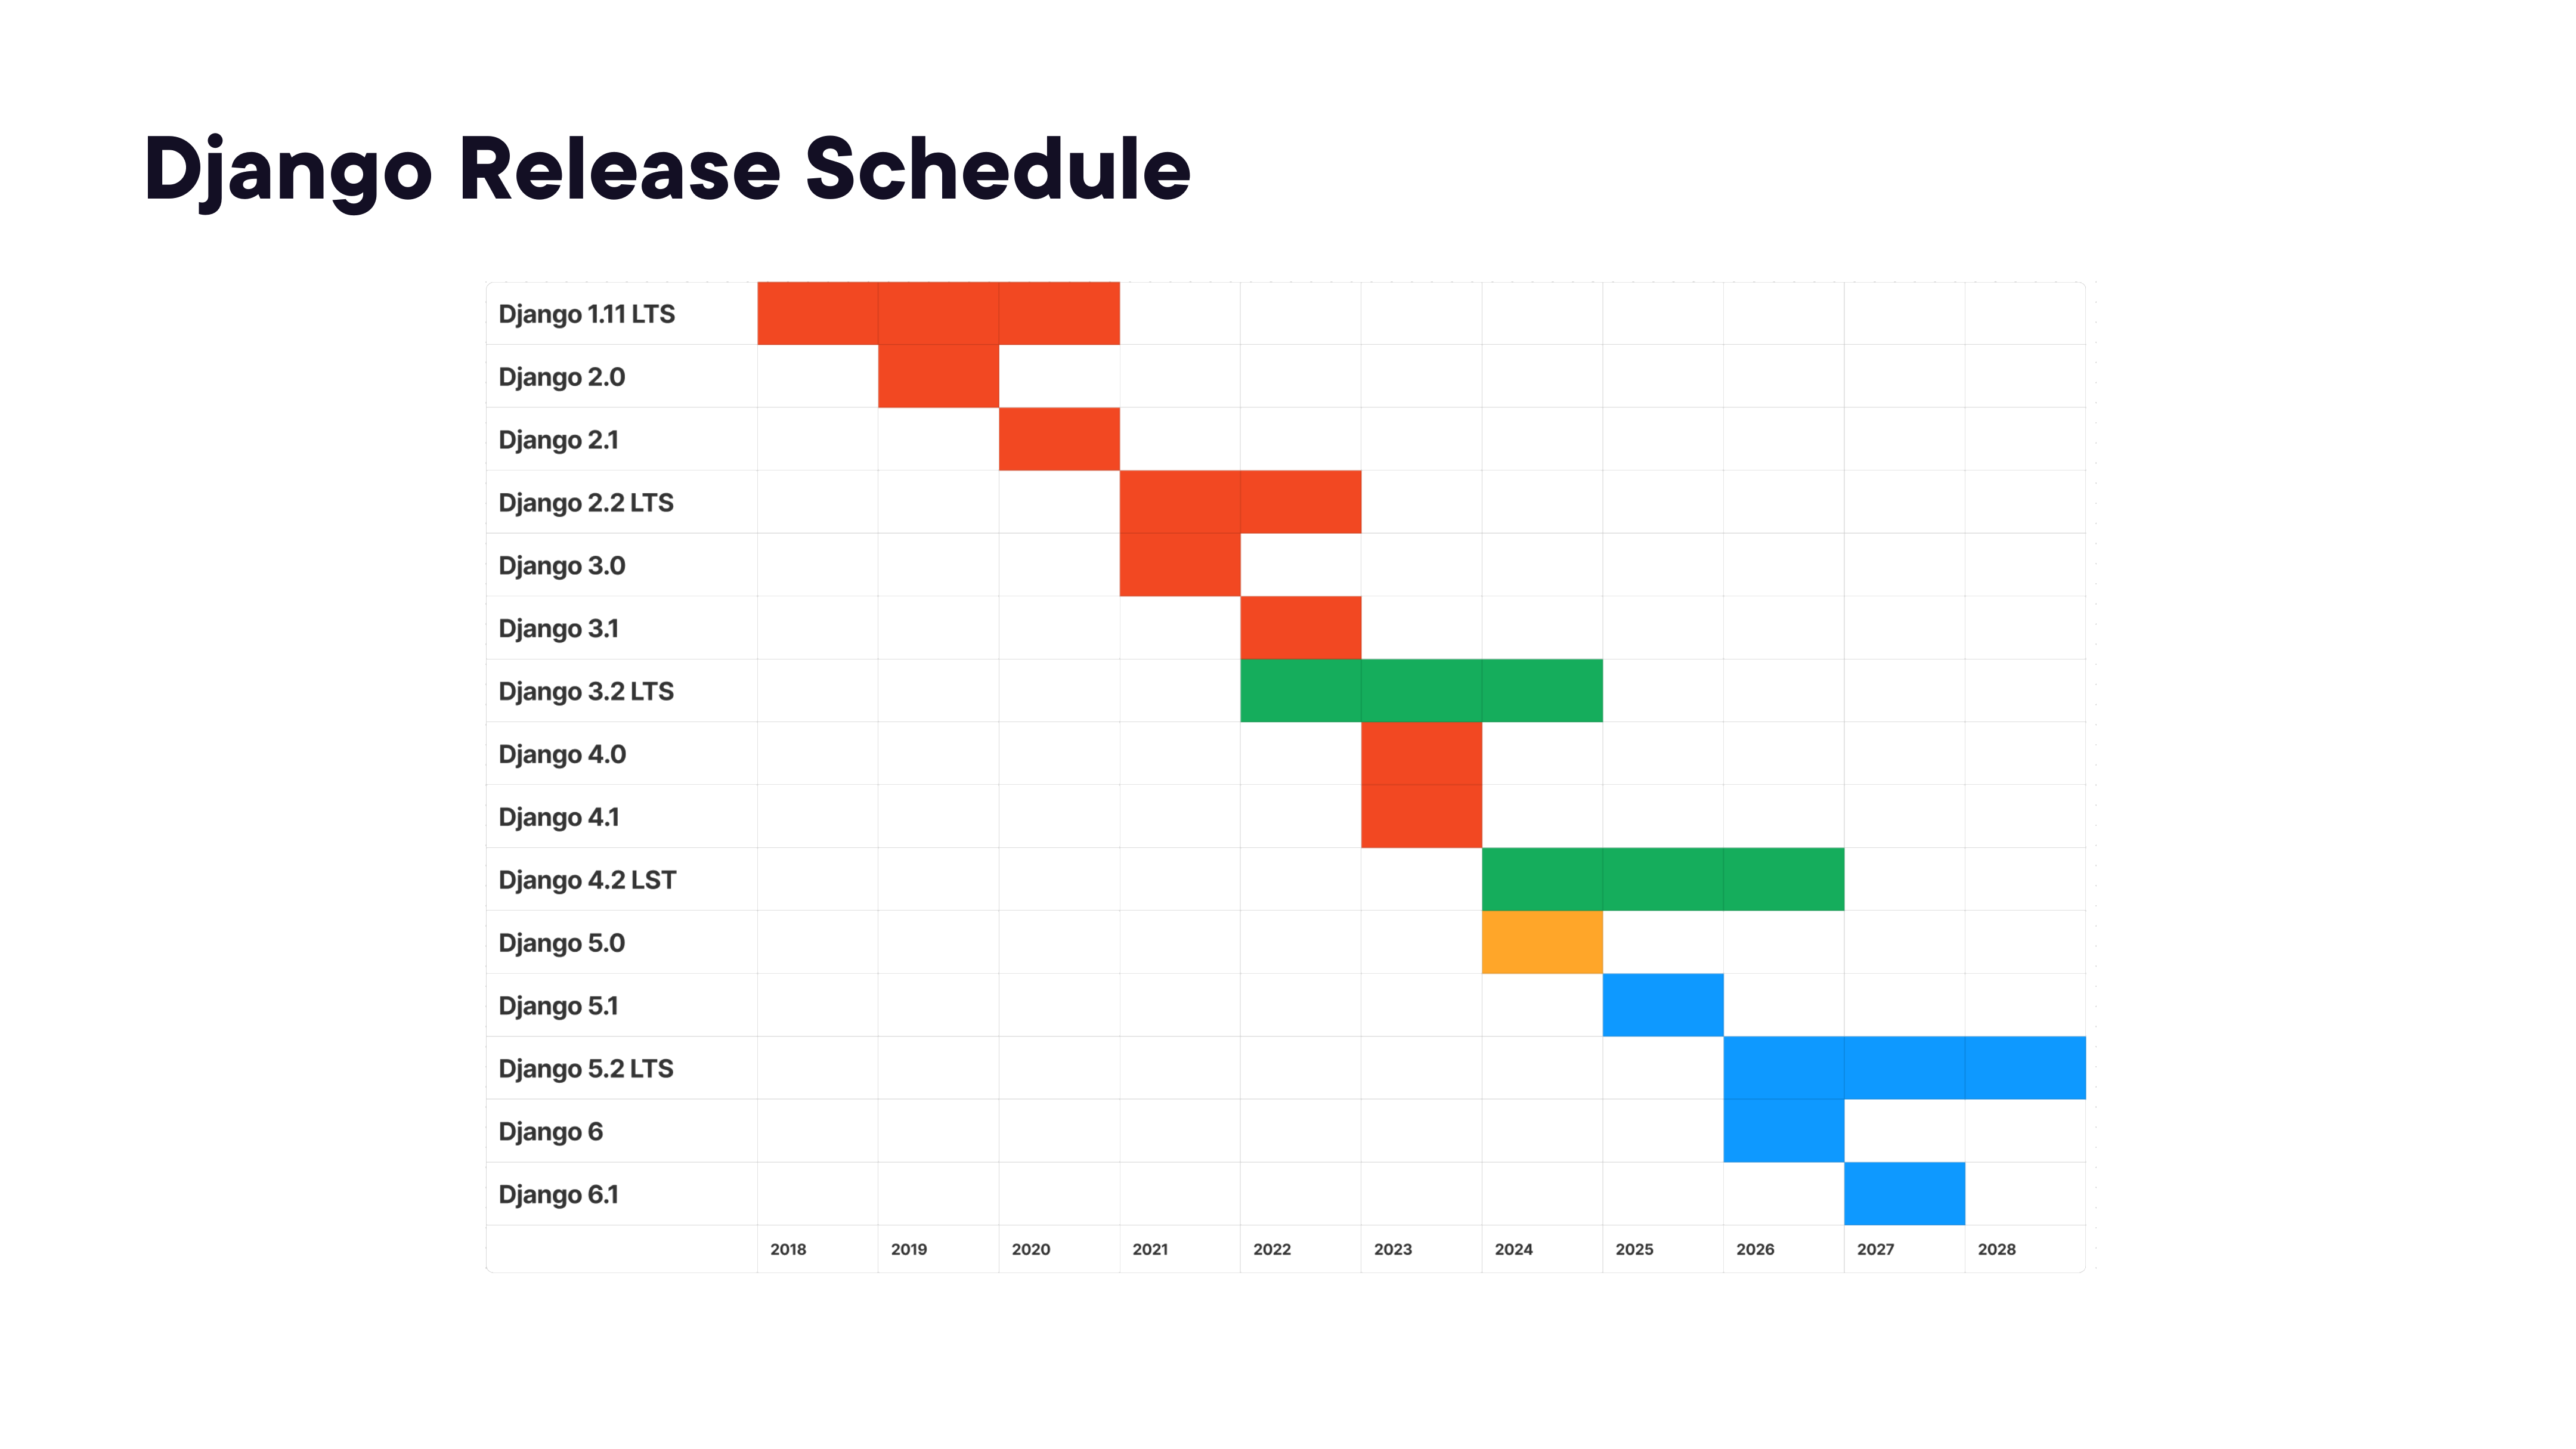

In [2]:
render_diagram(Path("assets/01-django-release-schedule.png"))

<a id="django-and-python-compatibility"></a>
### Django and Python Compatibility

Not every Django version supports every Python version. Always check compatibility before upgrading either.

#### Upgrade Process

1. **Read the release notes** — identify breaking changes and new deprecations
2. **Check dependencies** — verify all third-party packages support the target version
3. **Resolve deprecation warnings** — fix warnings from the current version before upgrading
4. **Upgrade via virtual environment** — test in isolation before touching production
5. **Test** — run the full test suite
6. **Deploy**


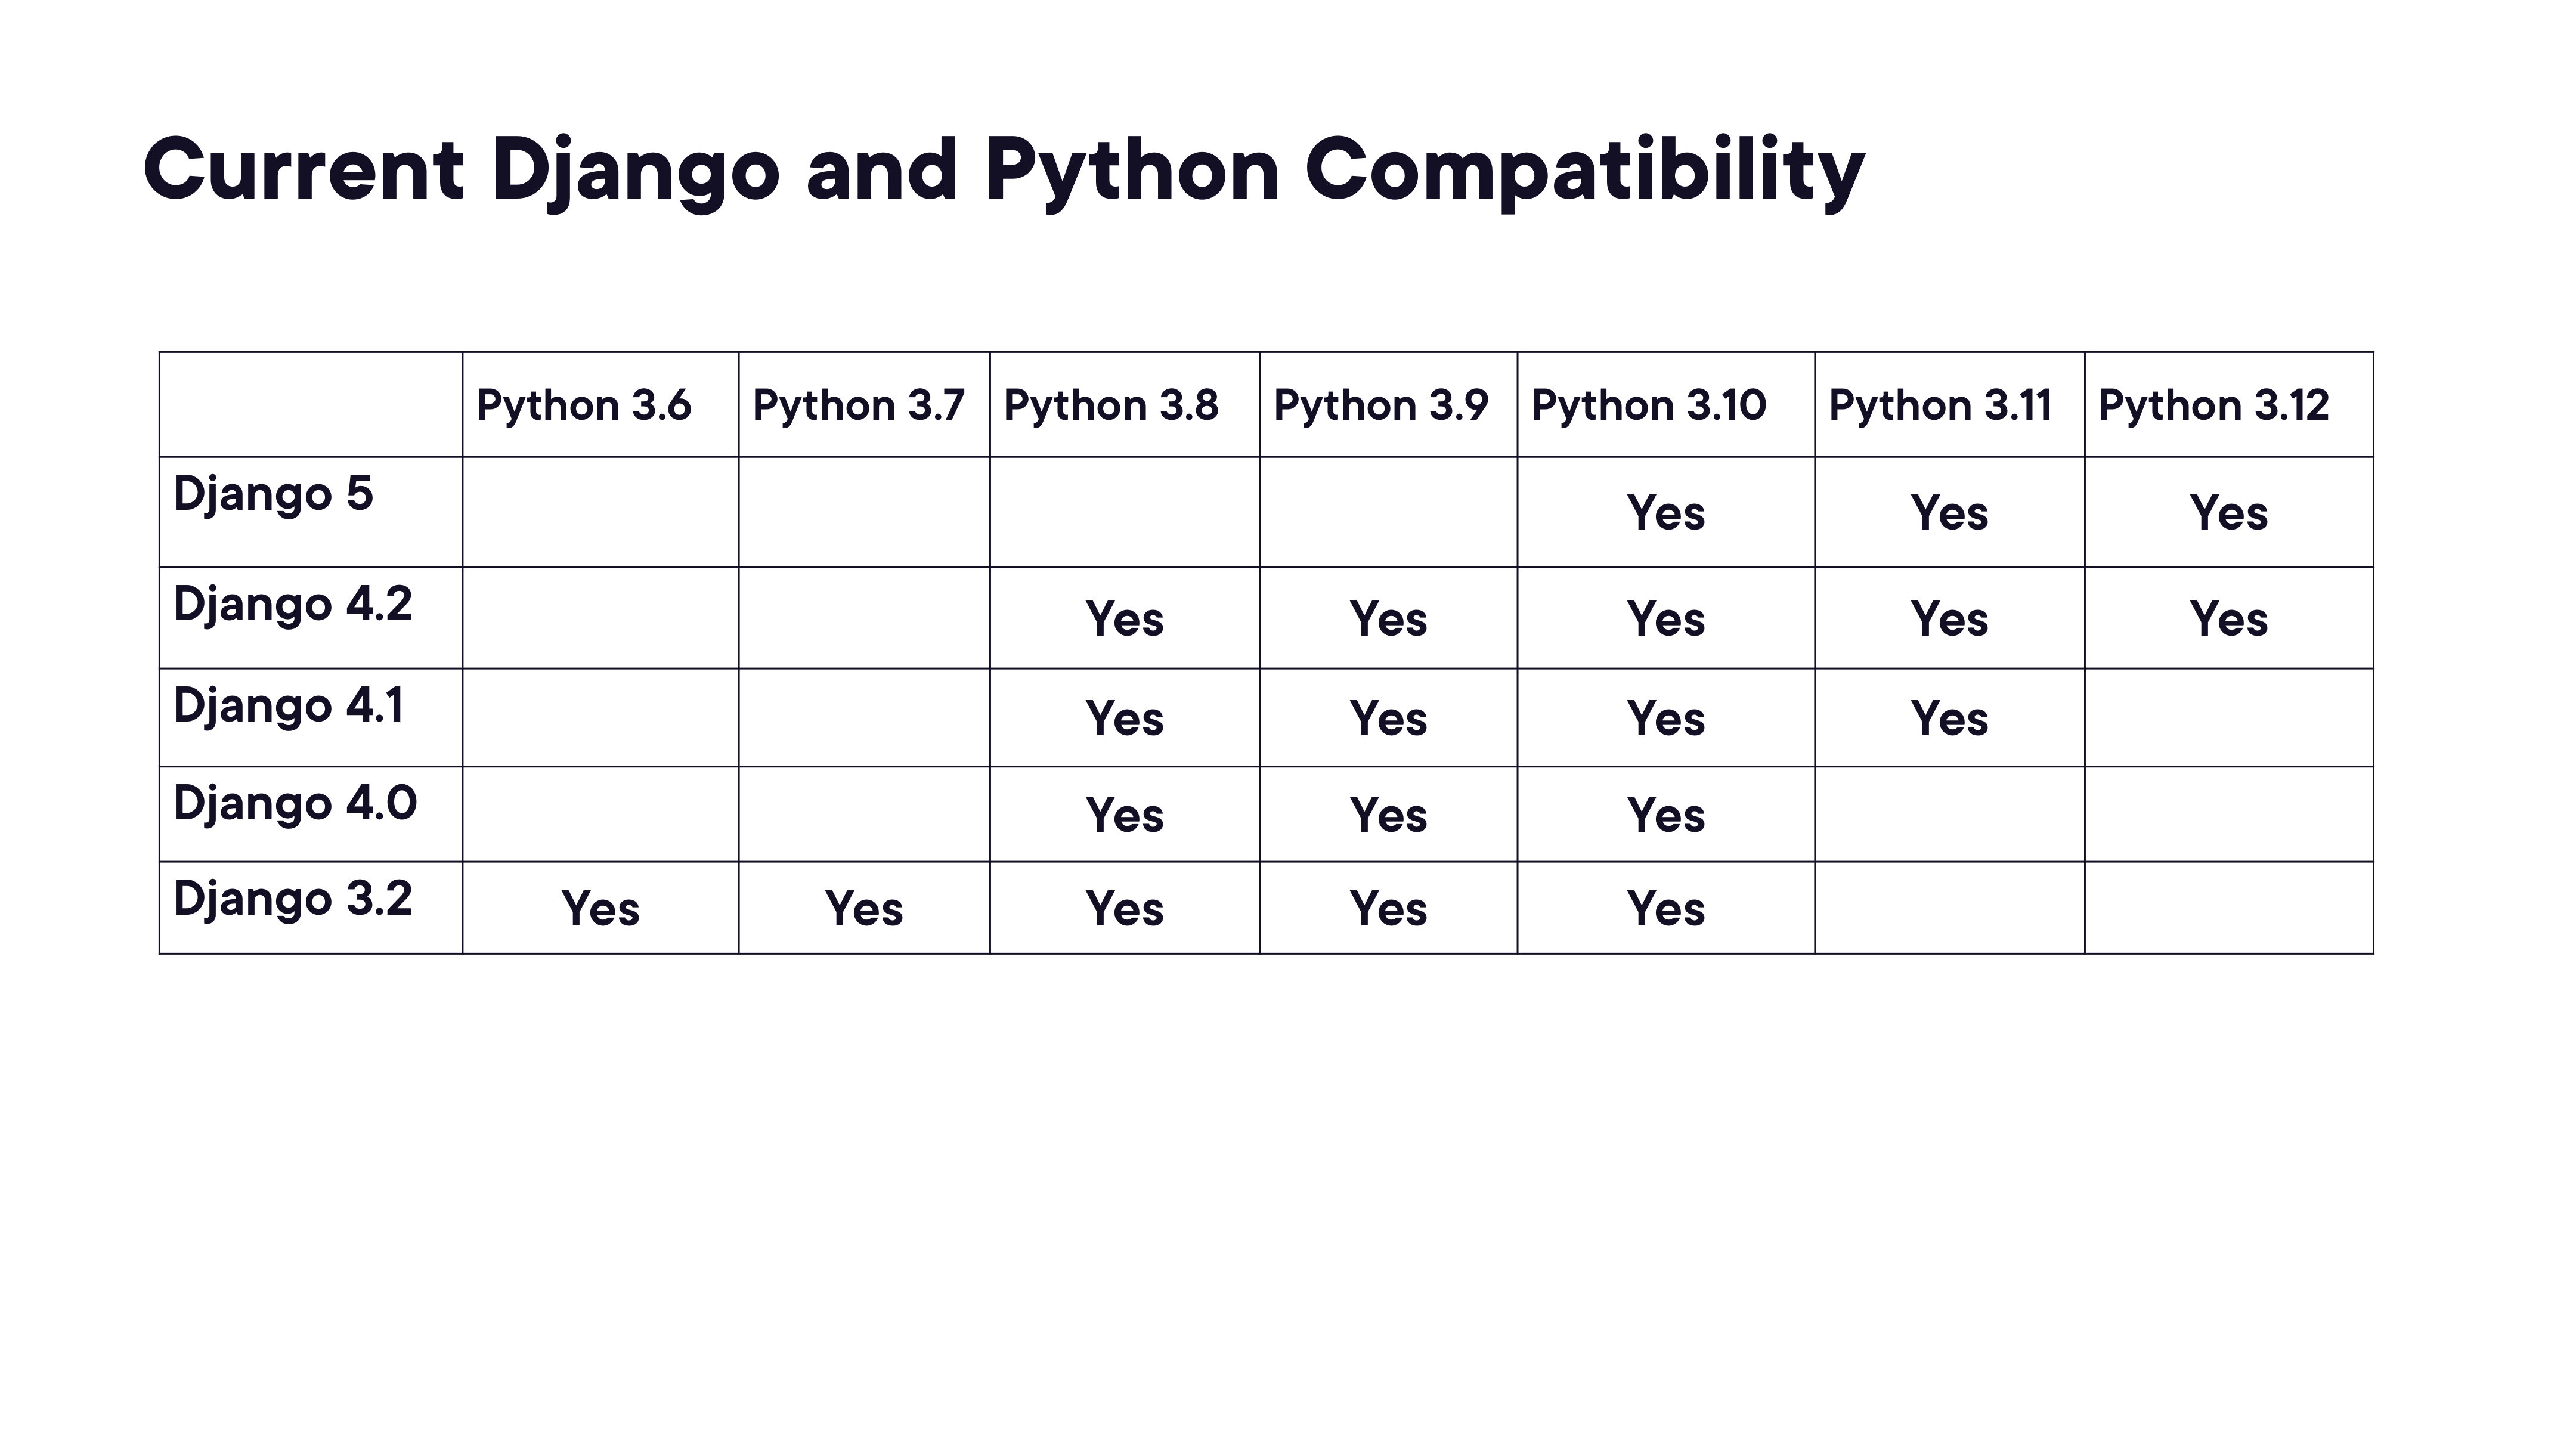

In [3]:
render_diagram(Path("assets/02-django-python-compatibility.png"))

#### Python Compatibility Considerations

- **Latest isn't always the greatest** — a new Python release may not yet be supported by all your dependencies
- **Check all project dependencies** — use `pip install --dry-run` or check each package's PyPI page
- **Leverage virtual environments** — test the upgrade in isolation before committing to it
- **Test, test, test** — run your full test suite against the candidate versions

<a id="deprecated-features"></a>
### Deprecated Features

Django follows a two-release deprecation cycle: a feature is deprecated in release `N`, a warning is shown in `N+1`, and the feature is removed in `N+2`. Staying on top of deprecations prevents expensive forced migrations later.

#### Deprecation Process

1. **Check release notes** — each release documents which features are newly deprecated
2. **Test for warnings** — run your test suite with deprecation warnings enabled
3. **Adjust code** — remove the deprecated usage before it becomes a breaking removal

#### Testing for Deprecation Warnings

**With Django's management commands:**
```bash
python -Wd manage.py check
python -Wd manage.py test
```

**With pytest:**
```bash
PYTHONWARNINGS=always pytest --capture=no
```

#### Example Deprecations (Django 5.x → 6.0)

| Feature | What changes | How to adapt |
|---|---|---|
| `forms.URLField` default scheme | Will change from `"http"` to `"https"` in Django 6.0 | Set `FORMS_URLFIELD_ASSUME_HTTPS = True` now to opt in during Django 5.x |
| `format_html()` without args | Will be removed | Remove any calls to `format_html()` that pass no `args` or `kwargs` |

**References:**
- [Django releases index](https://docs.djangoproject.com/en/5.0/releases/)
- [Django community](https://www.djangoproject.com/community/)

<a id="virtual-environments-for-upgrades"></a>
### Virtual Environments for Upgrades

Virtual environments let you maintain multiple isolated Python/Django installations side by side — critical for testing upgrades without disrupting a working project.

#### Working with Multiple Environments

Each virtual environment has its own Python interpreter and package set:

- **Virtual Environment 1**: Python 3.9, Django 3.2, jwt 1.2 (current production)
- **Virtual Environment 2**: Python 3.12, Django 5.0, jwt 1.8 (upgrade candidate)


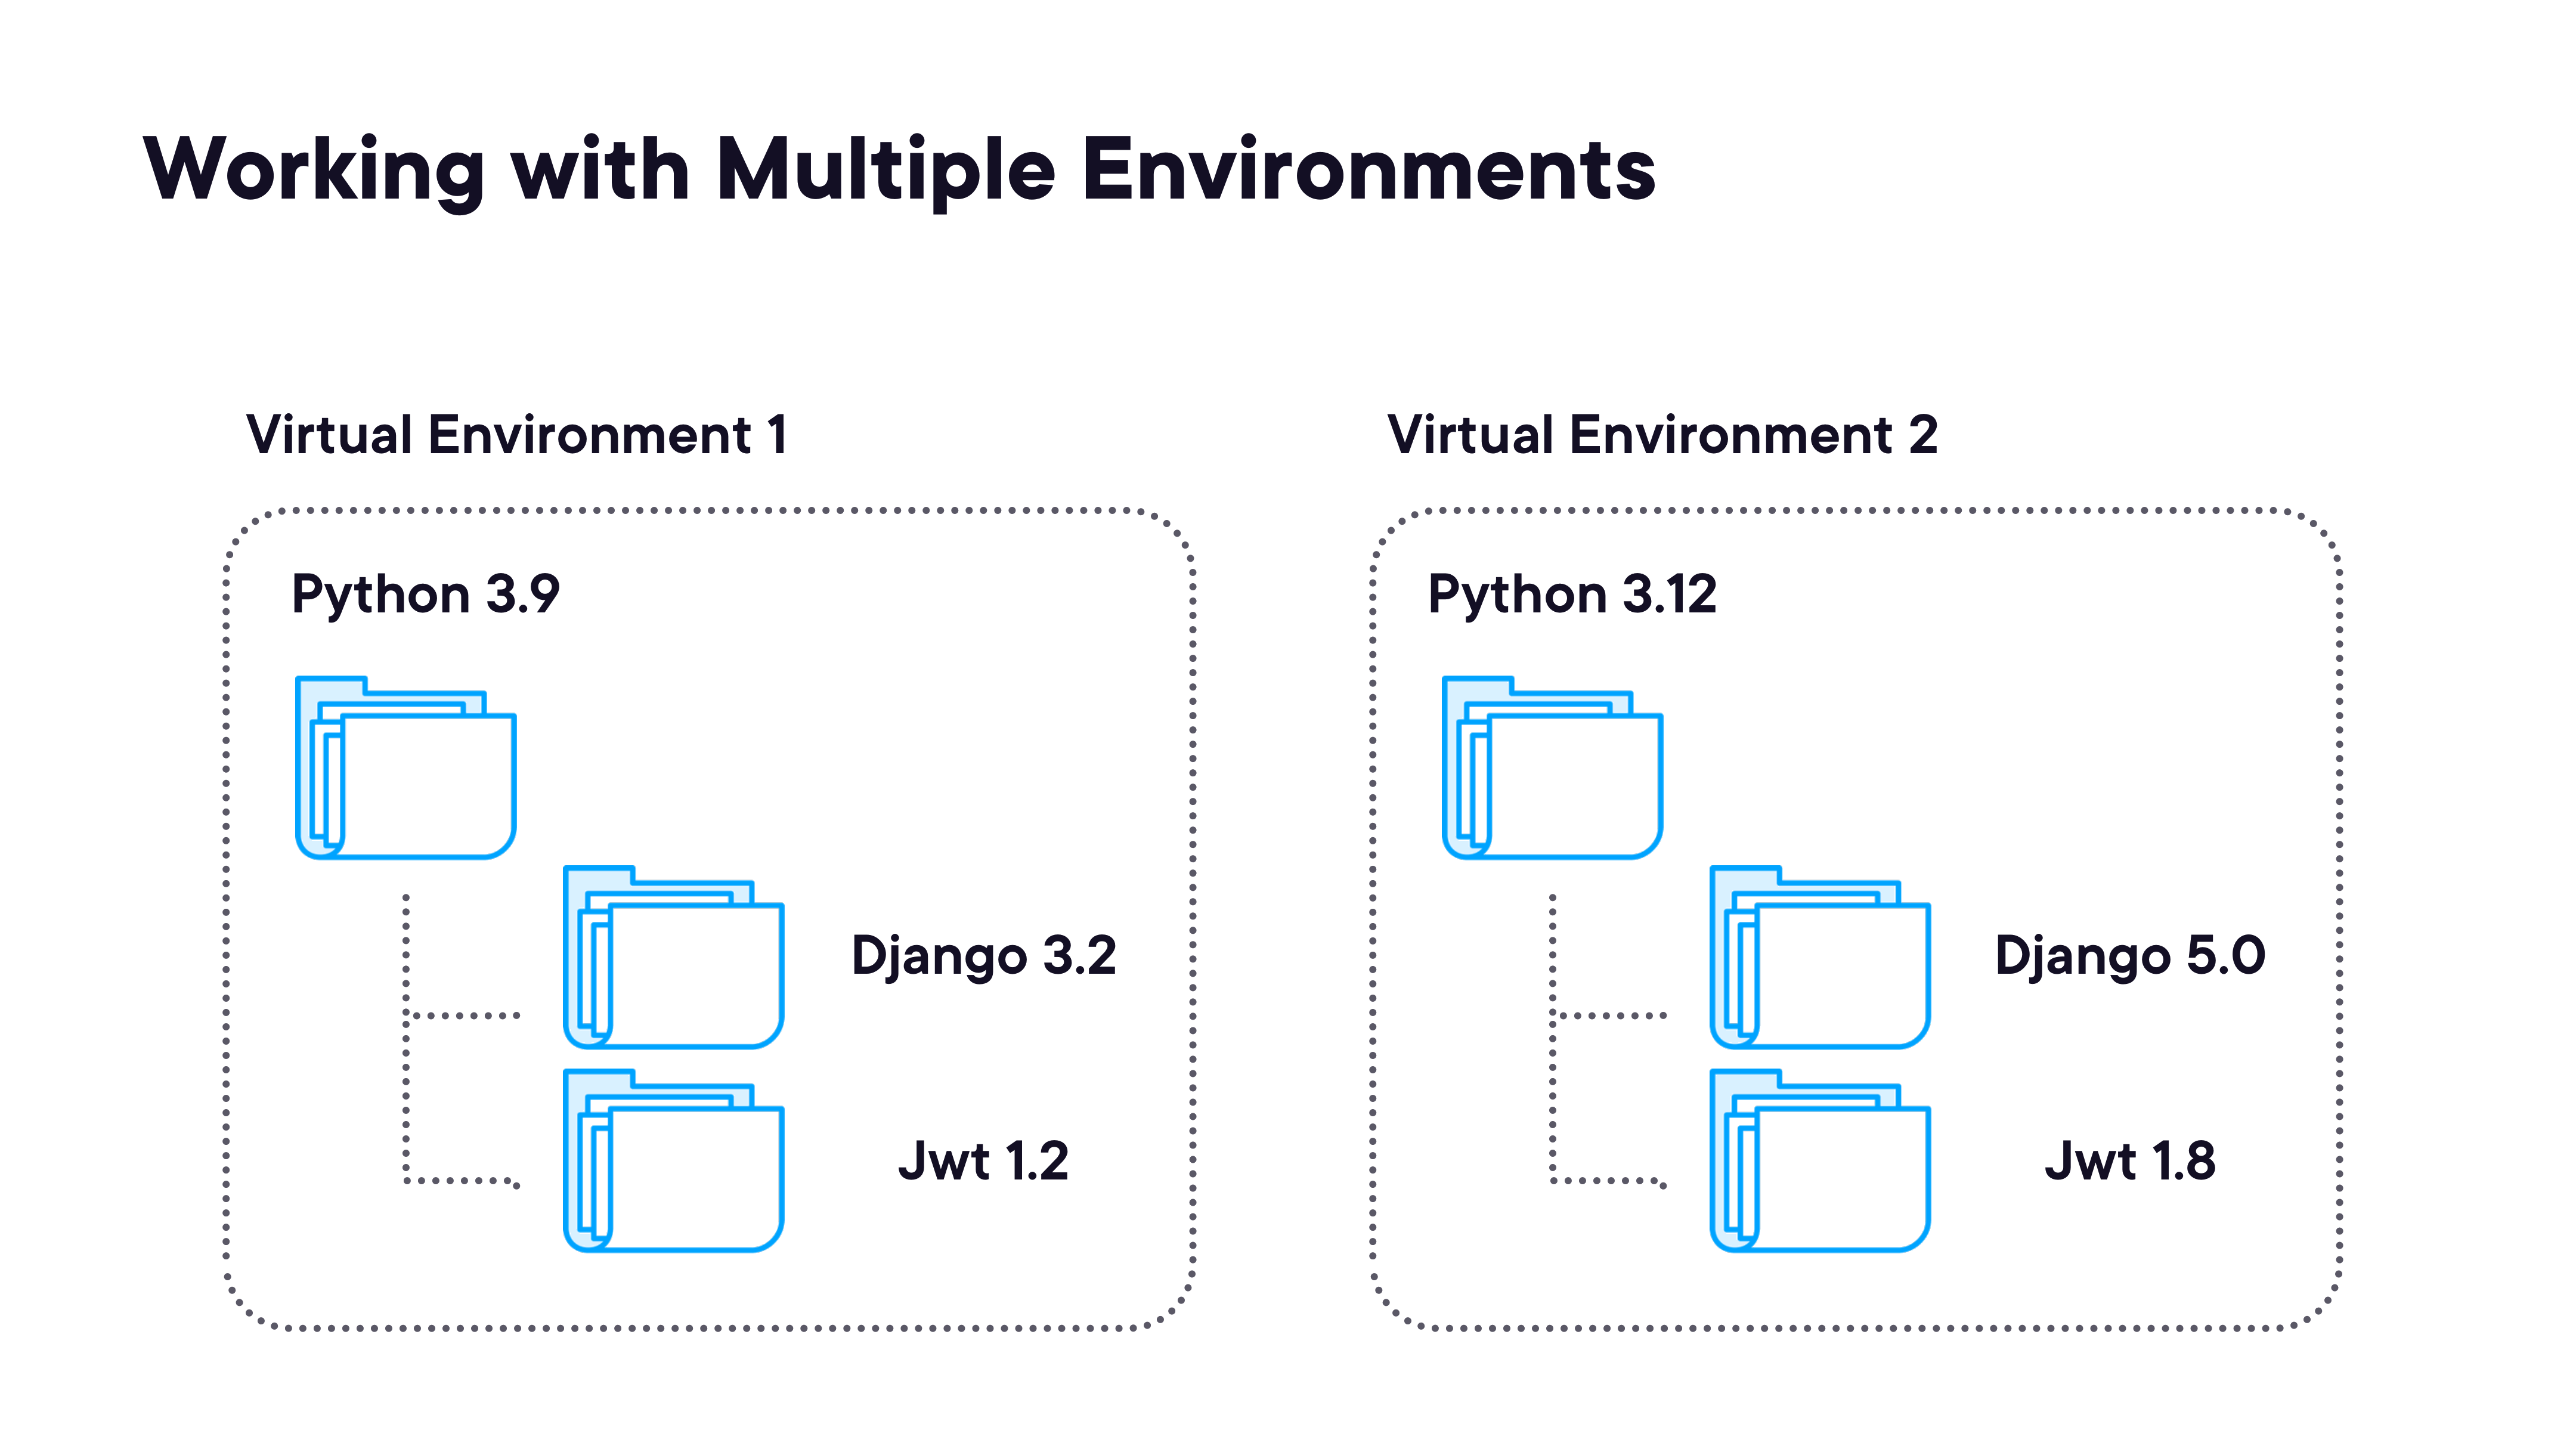

In [4]:
render_diagram(Path("assets/03-virtual-environments.png"))

#### Tools

| Tool | Purpose |
|---|---|
| **pyenv** | Manage multiple Python versions on the same machine |
| **virtualenv** | Create isolated virtual environments |
| **pip** | Install and manage Python packages within an environment |

#### Creating Two Environments for Testing an Upgrade

```bash
# Install pyenv (https://github.com/pyenv/pyenv)
pyenv install 3.11.0
pyenv install 3.12.0

# Create environment 1: Python 3.11 + Django 4.2 (LTS)
pyenv local 3.11.0
virtualenv venv311
source venv311/bin/activate
pip install "Django==4.2"
pip freeze > requirements-311.txt
deactivate

# Create environment 2: Python 3.12 + Django 5.0
pyenv local 3.12.0
virtualenv venv312
source venv312/bin/activate
pip install "Django==5.0"
pip freeze > requirements-312.txt
```

#### Final Steps Before Deploying an Upgrade

1. Review the Django docs for the target version
2. Run `python -Wd manage.py test` in the new environment and fix all failures
3. Run `python -Wd manage.py check --deploy` for production configuration warnings
4. Update your `requirements.txt` and commit
5. Deploy to staging first; validate before updating production

**Reference:** [pyenv on GitHub](https://github.com/pyenv/pyenv)